<a href="https://colab.research.google.com/github/SruthiAravind27/hcv-classifier/blob/main/HCV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas
import numpy as np
import re
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from scipy import stats
from pandas.api.types import is_numeric_dtype
from sklearn.model_selection import cross_val_score
from sklearn.exceptions import ConvergenceWarning
from pandas.api.types import is_numeric_dtype

# Modify this to point to your data.
unique_data = pandas.read_csv("HCV.csv")

unique_data

,Unnamed: 0,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
0,1,0=Blood Donor,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0
1,2,0=Blood Donor,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5
2,3,0=Blood Donor,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3
3,4,0=Blood Donor,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7
4,5,0=Blood Donor,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
610,611,3=Cirrhosis,62,f,32.0,416.6,5.9,110.3,50.0,5.57,6.30,55.7,650.9,68.5
611,612,3=Cirrhosis,64,f,24.0,102.8,2.9,44.4,20.0,1.54,3.02,63.0,35.9,71.3
612,613,3=Cirrhosis,64,f,29.0,87.3,3.5,99.0,48.0,1.66,3.63,66.7,64.2,82.0
613,614,3=Cirrhosis,46,f,33.0,NaN,39.0,62.0,20.0,3.56,4.20,52.0,50.0,71.0


In [ ]:
unique_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 615 entries, 0 to 614
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  615 non-null    int64  
 1   Category    615 non-null    object 
 2   Age         615 non-null    int64  
 3   Sex         615 non-null    object 
 4   ALB         614 non-null    float64
 5   ALP         597 non-null    float64
 6   ALT         614 non-null    float64
 7   AST         615 non-null    float64
 8   BIL         615 non-null    float64
 9   CHE         615 non-null    float64
 10  CHOL        605 non-null    float64
 11  CREA        615 non-null    float64
 12  GGT         615 non-null    float64
 13  PROT        614 non-null    float64
dtypes: float64(10), int64(2), object(2)
memory usage: 67.4+ KB


In [ ]:
def clean_data(frame):
    for col in frame.columns:
        c = frame[col]
        for i in range(len(c)):
            x = frame.loc[i, col]
            if isinstance(x, str):
                s = x.strip().lower()

                if s == "na":
                    frame.loc[i, col] = np.nan
                    continue
                pattern2 = r"^(-?\d+)[a-z]?=(.+)$"
                match2 = re.match(pattern2, s)

                if match2:
                    prefix_num = int(match2.group(1))
                    value = match2.group(2).strip()  # also clean the value

                    if prefix_num == 0:
                        frame.loc[i, col] = 0
                    elif prefix_num in [1, 2, 3]:
                        frame.loc[i, col] = 1
                """pattern2 = r"^(-?\d+)[a-z]?=(.+)$"
                match2 = re.match(pattern2, s)
                if match2 is not None:
                    if s.startswith("0=") or s.startswith("0s"):
                        frame.loc[i, col] = 0
                    elif s.startswith("1=") or s.startswith("2=") or s.startswith("3="):
                        frame.loc[i, col] = 1"""
    return frame
unique_data = clean_data(unique_data)
print(unique_data.iloc[535])
unique_data

Unnamed: 0     536
Category         0
Age             49
Sex              m
ALB           21.6
ALP           42.2
ALT            9.5
AST           10.6
BIL            2.4
CHE           3.75
CHOL          3.01
CREA          64.0
GGT           38.9
PROT          44.8
Name: 535, dtype: object


,Unnamed: 0,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
0,1,0,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0
1,2,0,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5
2,3,0,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3
3,4,0,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7
4,5,0,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
610,611,1,62,f,32.0,416.6,5.9,110.3,50.0,5.57,6.30,55.7,650.9,68.5
611,612,1,64,f,24.0,102.8,2.9,44.4,20.0,1.54,3.02,63.0,35.9,71.3
612,613,1,64,f,29.0,87.3,3.5,99.0,48.0,1.66,3.63,66.7,64.2,82.0
613,614,1,46,f,33.0,NaN,39.0,62.0,20.0,3.56,4.20,52.0,50.0,71.0


In [ ]:
unique_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 615 entries, 0 to 614
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  615 non-null    int64  
 1   Category    615 non-null    object 
 2   Age         615 non-null    int64  
 3   Sex         615 non-null    object 
 4   ALB         614 non-null    float64
 5   ALP         597 non-null    float64
 6   ALT         614 non-null    float64
 7   AST         615 non-null    float64
 8   BIL         615 non-null    float64
 9   CHE         615 non-null    float64
 10  CHOL        605 non-null    float64
 11  CREA        615 non-null    float64
 12  GGT         615 non-null    float64
 13  PROT        614 non-null    float64
dtypes: float64(10), int64(2), object(2)
memory usage: 67.4+ KB


Text(0.5, 0, 'ALB')

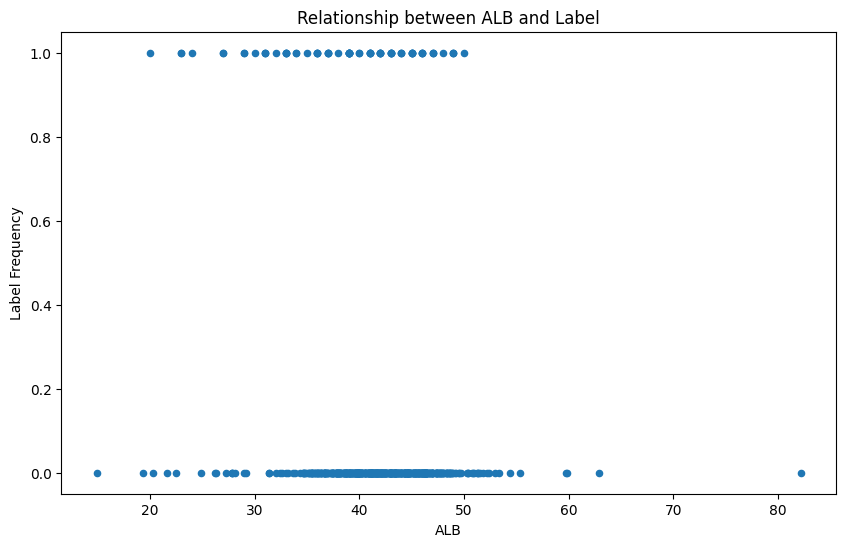

In [ ]:
new = unique_data.plot.scatter(x = 'ALB', y = 'Category', figsize=(10, 6)) # Increase figure size

# Rotate the x-axis labels

new.set_title('Relationship between ALB and Label')
new.set_ylabel('Label Frequency')
new.set_xlabel('ALB')


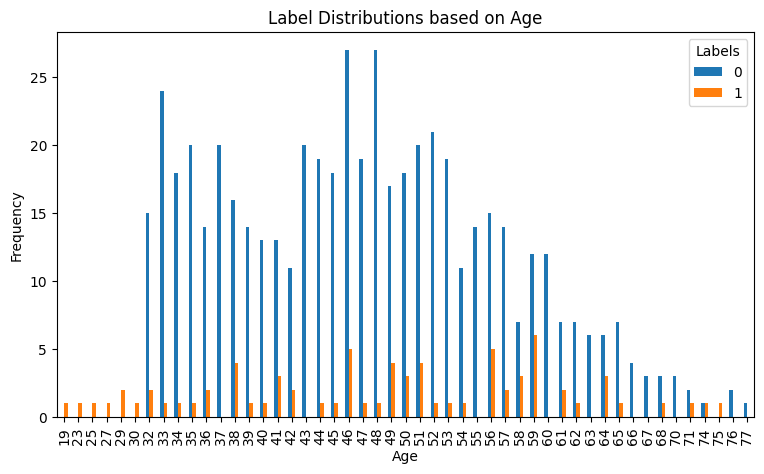

In [ ]:
counts = unique_data.groupby(['Age', 'Category']).size().unstack()

new = counts.plot.bar(figsize=(9, 5), title='Label Distributions based on Age', legend=True)

new.set_ylabel('Frequency')
new.legend(title='Labels')

In [ ]:
def create_classifiers():
    classifier_list = [LogisticRegression(random_state=42, max_iter = 1000), RandomForestClassifier(random_state=42), KNeighborsClassifier()]
    return classifier_list

my_classifiers = create_classifiers()
my_classifiers

[LogisticRegression(max_iter=1000, random_state=42),
 RandomForestClassifier(random_state=42),
 KNeighborsClassifier()]

In [ ]:
def cross_fold_validation(classifier, frame, folds):
    for col in frame.columns:
        if is_numeric_dtype(frame[col]):
              if frame[col].isna().sum() > 0:
                  frame[col] = frame[col].astype(float).fillna(frame[col].mean())
        else:
          mode_value = frame[col].mode()
          if not mode_value.empty:
                    frame[col] = frame[col].fillna(mode_value[0])

    # one hot encoding
    one_hot_cols = frame.select_dtypes(include = 'object').columns
    frame = pandas.get_dummies(frame, columns = one_hot_cols, dummy_na = True)

    df = frame.copy()

    for c in df.columns:
        if is_numeric_dtype(df[c]):
            if df[c].isna().sum() > 0:
                df[c] = df[c].astype(float).fillna(df[c].mean())
        else:
            pass

    features = df.drop('Category', axis = 1)
    label = df['Category']

    scoring = cross_val_score(classifier, features, label, cv = folds,
                              scoring = 'accuracy')
    accuracy_list = []
    for i in scoring:
        accuracy_list.append(i)
    return accuracy_list

my_classifiers_scores = []
for classifier in my_classifiers:
    accuracy_scores = cross_fold_validation(classifier, unique_data, 5)
    mean_accuracy = np.mean(accuracy_scores)
    std_accuracy = np.std(accuracy_scores)
    my_classifiers_scores.append(accuracy_scores)
    print("Classifier: %s, Accuracy: %s." % (type(classifier).__name__, accuracy_scores))
    print("Classifier: %s, Mean Accuracy: %.3f, Standard Deviation: %.3f." % (type(classifier).__name__, mean_accuracy, std_accuracy))

data = {
    "Model": ["Logistic Regression", "K–Nearest Neighbor", "Random Forest"],
    "Mean Accuracy": [0.980, 0.925, 0.902],
    "Standard Deviation of Accuracy": [0.035, 0.138, 0.168]
}

df = pd.DataFrame(data)

# Display the table
print("Model Accuracy:")
display(df)

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

Classifier: LogisticRegression, Accuracy: [np.float64(1.0), np.float64(1.0), np.float64(0.991869918699187), np.float64(1.0), np.float64(0.9105691056910569)].
Classifier: LogisticRegression, Mean Accuracy: 0.980, Standard Deviation: 0.035.
Classifier: RandomForestClassifier, Accuracy: [np.float64(0.943089430894309), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(0.5691056910569106)].
Classifier: RandomForestClassifier, Mean Accuracy: 0.902, Standard Deviation: 0.168.
Classifier: KNeighborsClassifier, Accuracy: [np.float64(0.975609756097561), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(0.6504065040650406)].
Classifier: KNeighborsClassifier, Mean Accuracy: 0.925, Standard Deviation: 0.138.
Model Accuracy:


,Model,Mean Accuracy,Standard Deviation of Accuracy
0,Logistic Regression,0.980,0.035
1,K–Nearest Neighbor,0.925,0.138
2,Random Forest,0.902,0.168


In [ ]:
def significance_test(a_values, b_values, p_value):
    stat, pvalue = stats.ttest_ind(a_values, b_values, equal_var = True)
    if pvalue < p_value:
        return True
    else:
        return False


for i in range(len(my_classifiers)):
    for j in range(i + 1, len(my_classifiers)):
        significant = significance_test(my_classifiers_scores[i], my_classifiers_scores[j], 0.10)
        print("%s vs %s: %s" % (type(my_classifiers[i]).__name__,
                                type(my_classifiers[j]).__name__, significant))

LogisticRegression vs RandomForestClassifier: False
LogisticRegression vs KNeighborsClassifier: False
RandomForestClassifier vs KNeighborsClassifier: False
